# Bước 1. Phân tích thăm dò (EDA) và tiền xử lý dữ liệu

Bộ dữ liệu: **Superstore Sales** (Kaggle `rohitsahoo/sales-forecasting`), file `train.csv`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110
pd.set_option('display.float_format', '{:,.3f}'.format)

## 1. Đọc và mô tả dữ liệu

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Master_UEH_MIS/semester 01/04. Khai phá dữ liệu nâng cao/Đồ án/data/train.csv', dtype={'Postal Code': str})
df.shape

(9800, 18)

In [ ]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.960
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.940
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.620
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.577
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   object 
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

Mô tả các cột phân loại: số giá trị khác nhau (`unique`), giá trị xuất hiện nhiều nhất (`top`) và số lần xuất hiện (`freq`).

In [ ]:
df.describe(include='object')

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name
count,9800,9800,9800,9800,9800,9800,9800,9800,9800,9800,9789,9800,9800,9800,9800,9800
unique,4922,1230,1326,4,793,793,3,1,529,49,626,4,1861,3,17,1849
top,CA-2018-100111,05/09/2017,26/09/2018,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,10035,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope
freq,14,38,34,5859,35,35,5101,9800,891,1946,253,3140,19,5909,1492,47


Mô tả cột số:

In [ ]:
df[['Sales']].describe()

,Sales
count,"9,800.000"
mean,230.769
std,626.652
min,0.444
25%,17.248
50%,54.490
75%,210.605
max,"22,638.480"


### Kiểm tra chất lượng

In [ ]:
df.isna().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [ ]:
df[df['Postal Code'].isna()][['City', 'State']].drop_duplicates()

,City,State
2234,Burlington,Vermont


In [ ]:
# Dòng trùng (so sánh mọi cột trừ Row ID)
df.drop(columns='Row ID').duplicated().sum()

np.int64(1)

In [ ]:
# Một mã sản phẩm có gắn với nhiều tên không?
ten_moi_ma = df.groupby('Product ID')['Product Name'].nunique()
(ten_moi_ma > 1).sum()

np.int64(32)

## 2. Thống kê mô tả và trực quan hóa

In [ ]:
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)
df['ship_days'] = (df['Ship Date'] - df['Order Date']).dt.days
df[['Order Date', 'Ship Date', 'ship_days']].describe()

,Order Date,Ship Date,ship_days
count,9800,9800,"9,800.000"
mean,2017-05-01 05:13:51.673469440,2017-05-05 04:17:52.653061120,3.961
min,2015-01-03 00:00:00,2015-01-07 00:00:00,0.000
25%,2016-05-24 00:00:00,2016-05-27 18:00:00,3.000
50%,2017-06-26 00:00:00,2017-06-29 00:00:00,4.000
75%,2018-05-15 00:00:00,2018-05-19 00:00:00,5.000
max,2018-12-30 00:00:00,2019-01-05 00:00:00,7.000
std,NaN,NaN,1.750


### 2.1. Phân phối Sales

In [ ]:
print('Độ lệch (skewness):', round(df['Sales'].skew(), 2))

q1 = df['Sales'].quantile(0.25)
q3 = df['Sales'].quantile(0.75)
nguong = q3 + 1.5 * (q3 - q1)
print('Ngưỡng ngoại lai (IQR):', round(nguong, 2))
print('Số dòng ngoại lai:', (df['Sales'] > nguong).sum())

Độ lệch (skewness): 12.98
Ngưỡng ngoại lai (IQR): 500.64
Số dòng ngoại lai: 1145


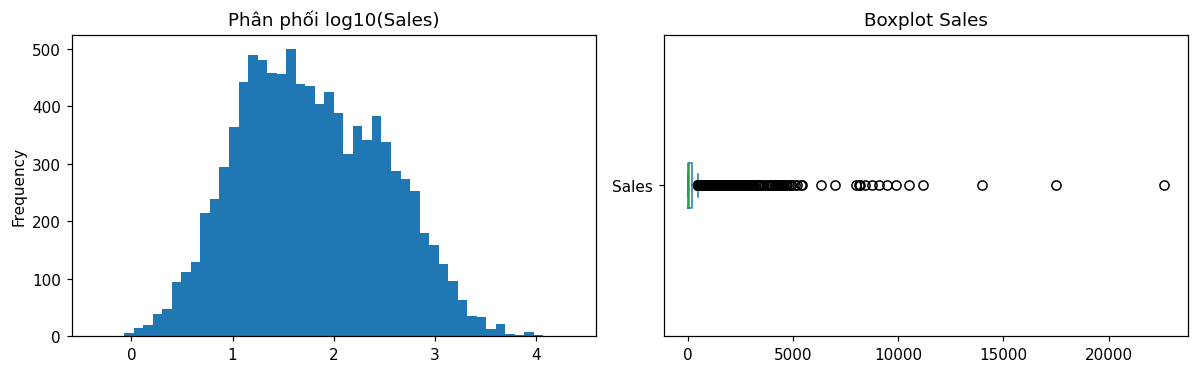

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
np.log10(df['Sales']).plot(kind='hist', bins=50, ax=ax[0], title='Phân phối log10(Sales)')
df['Sales'].plot(kind='box', vert=False, ax=ax[1], title='Boxplot Sales')
plt.tight_layout()

### 2.2. Theo Category và Sub-Category

In [ ]:
theo_cat = df.groupby('Category')['Sales'].agg(['sum', 'count'])
theo_cat['ty_trong_doanh_thu'] = theo_cat['sum'] / theo_cat['sum'].sum()
theo_cat['ty_trong_so_dong'] = theo_cat['count'] / theo_cat['count'].sum()
theo_cat

,sum,count,ty_trong_doanh_thu,ty_trong_so_dong
Category,,,,
Furniture,"728,658.576",2078,0.322,0.212
Office Supplies,"705,422.334",5909,0.312,0.603
Technology,"827,455.873",1813,0.366,0.185


In [ ]:
theo_sub = df.groupby('Sub-Category')['Sales'].agg(['sum', 'count', 'median']).sort_values('sum')
theo_sub

,sum,count,median
Sub-Category,,,
Fasteners,"3,001.960",214,10.584
Labels,"12,347.726",357,14.940
Envelopes,"16,128.046",248,28.576
Art,"26,705.410",785,15.480
Supplies,"46,420.308",184,27.645
Paper,"76,828.304",1338,26.720
Furnishings,"89,212.018",931,41.960
Appliances,"104,618.403",459,83.420
Bookcases,"113,813.199",226,304.457


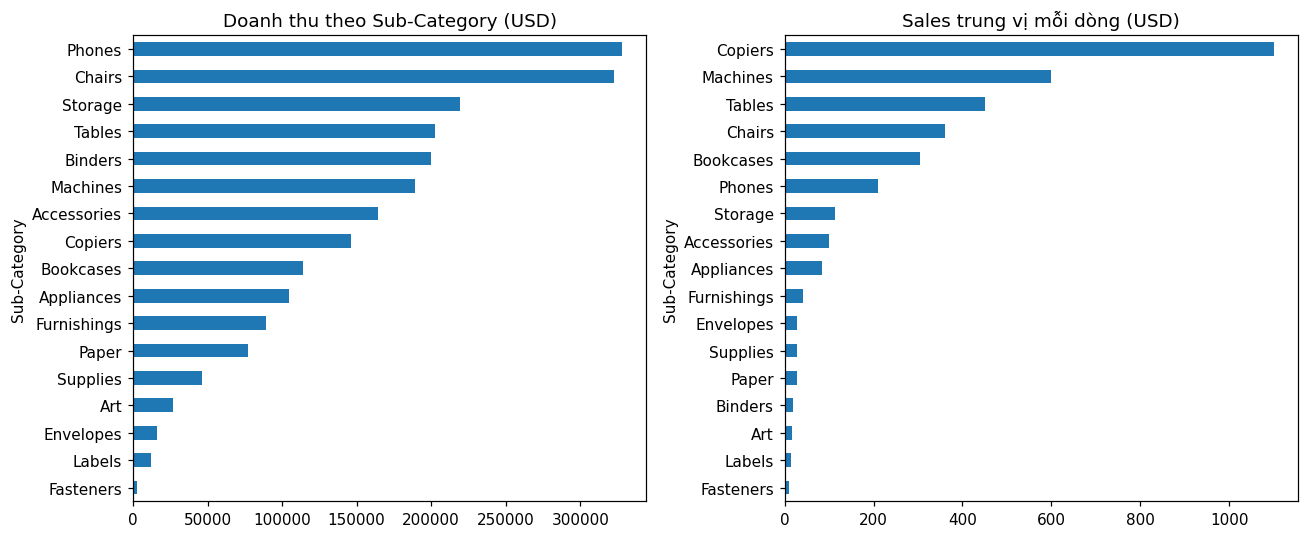

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
theo_sub['sum'].plot(kind='barh', ax=ax[0], title='Doanh thu theo Sub-Category (USD)')
theo_sub['median'].sort_values().plot(kind='barh', ax=ax[1], title='Sales trung vị mỗi dòng (USD)')
plt.tight_layout()

### 2.3. Theo Region, Segment, Ship Mode

In [ ]:
for cot in ['Region', 'Segment', 'Ship Mode']:
    bang = df.groupby(cot).agg(doanh_thu=('Sales', 'sum'), so_don=('Order ID', 'nunique'))
    bang['ty_trong'] = bang['doanh_thu'] / bang['doanh_thu'].sum()
    bang['doanh_thu_moi_don'] = bang['doanh_thu'] / bang['so_don']
    display(bang.sort_values('doanh_thu', ascending=False))

,doanh_thu,so_don,ty_trong,doanh_thu_moi_don
Region,,,,
West,"710,219.684",1587,0.314,447.523
East,"669,518.726",1369,0.296,489.057
Central,"492,646.913",1156,0.218,426.165
South,"389,151.459",810,0.172,480.434


,doanh_thu,so_don,ty_trong,doanh_thu_moi_don
Segment,,,,
Consumer,"1,148,060.531",2537,0.508,452.527
Corporate,"688,494.075",1491,0.304,461.767
Home Office,"424,982.177",894,0.188,475.372


,doanh_thu,so_don,ty_trong,doanh_thu_moi_don
Ship Mode,,,,
Standard Class,"1,340,831.307",2945,0.593,455.291
Second Class,"449,914.179",944,0.199,476.604
First Class,"345,572.257",772,0.153,447.632
Same Day,"125,219.039",261,0.055,479.766


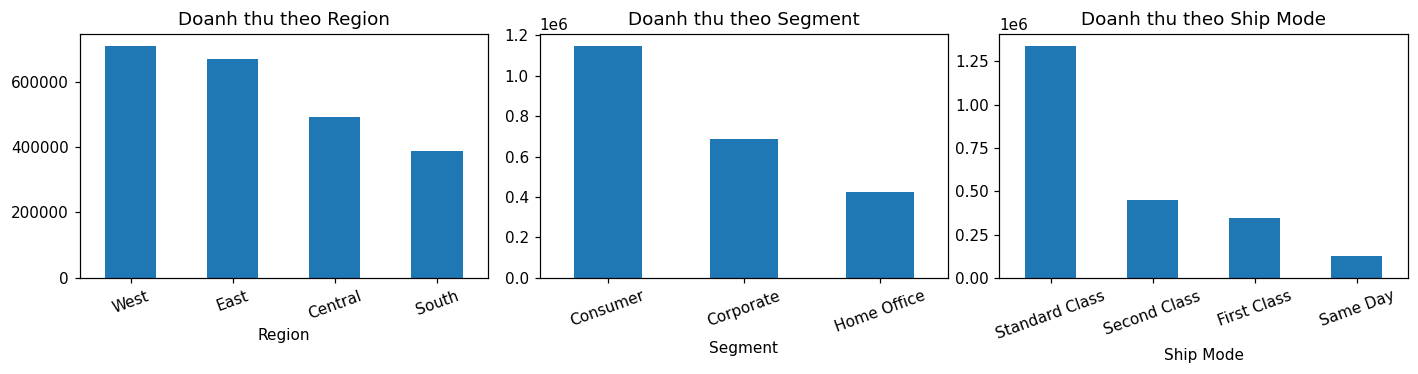

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for i, cot in enumerate(['Region', 'Segment', 'Ship Mode']):
    df.groupby(cot)['Sales'].sum().sort_values(ascending=False).plot(kind='bar', ax=ax[i], title=f'Doanh thu theo {cot}', rot=20)
plt.tight_layout()

### 2.4. Theo thời gian

In [ ]:
df['nam'] = df['Order Date'].dt.year
df['quy'] = df['Order Date'].dt.quarter

theo_nam = df.groupby('nam').agg(doanh_thu=('Sales', 'sum'), so_don=('Order ID', 'nunique'))
theo_nam['tang_truong'] = theo_nam['doanh_thu'].pct_change()
theo_nam

,doanh_thu,so_don,tang_truong
nam,,,
2015,"479,856.208",947,NaN
2016,"459,436.005",1019,-0.043
2017,"600,192.550",1295,0.306
2018,"722,052.019",1661,0.203


In [ ]:
theo_quy = df.groupby('quy')['Sales'].sum()
theo_quy / theo_quy.sum()

,Sales
quy,
1,0.155
2,0.193
3,0.267
4,0.385


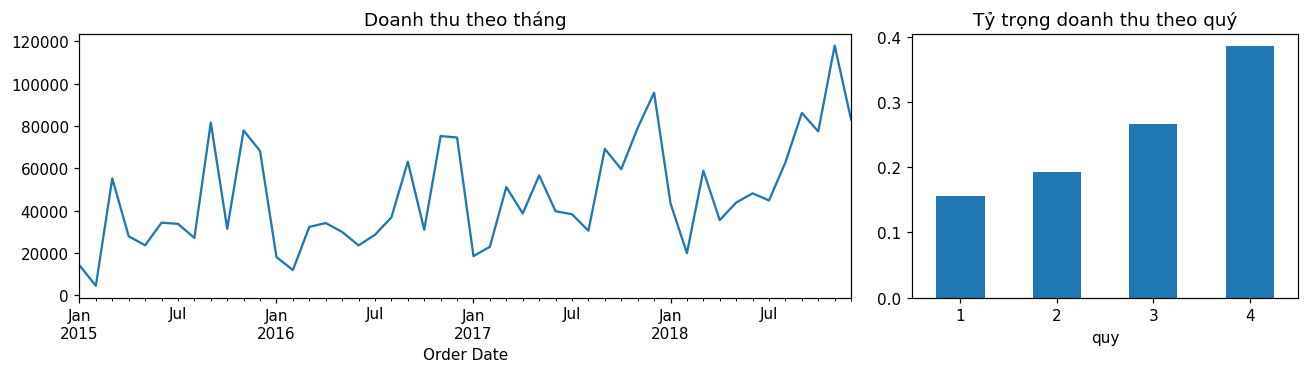

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={'width_ratios': [2, 1]})
df.set_index('Order Date')['Sales'].resample('MS').sum().plot(ax=ax[0], title='Doanh thu theo tháng')
(theo_quy / theo_quy.sum()).plot(kind='bar', ax=ax[1], title='Tỷ trọng doanh thu theo quý', rot=0)
plt.tight_layout()

### 2.5. Số ngày giao hàng

In [ ]:
don = df.drop_duplicates('Order ID')
don.groupby('Ship Mode')['ship_days'].describe()

,count,mean,std,min,25%,50%,75%,max
Ship Mode,,,,,,,,
First Class,772.000,2.185,0.764,1.000,2.000,2.000,3.000,4.000
Same Day,261.000,0.046,0.210,0.000,0.000,0.000,0.000,1.000
Second Class,944.000,3.237,1.174,1.000,2.000,3.000,4.000,5.000
Standard Class,"2,945.000",5.001,1.007,3.000,4.000,5.000,6.000,7.000


## 3. Cấu trúc ở mức đơn hàng và nhãn phân lớp

Bài toán phân lớp làm ở mức đơn hàng: **đơn giá trị cao** = tổng Sales của đơn lớn hơn trung vị.
Ở đây trung vị tính trên toàn bộ dữ liệu chỉ để xem mức cân bằng; khi huấn luyện mô hình, trung vị tính trên tập train.

In [ ]:
orders = df.groupby('Order ID').agg(
    order_sales=('Sales', 'sum'),
    n_lines=('Sales', 'count'),
    n_subcats=('Sub-Category', 'nunique'))

trung_vi = orders['order_sales'].median()
orders['high_value'] = (orders['order_sales'] > trung_vi).astype(int)

print('Trung vị giá trị đơn:', round(trung_vi, 2))
orders.describe()

Trung vị giá trị đơn: 151.88


,order_sales,n_lines,n_subcats,high_value
count,"4,922.000","4,922.000","4,922.000","4,922.000"
mean,459.475,1.991,1.826,0.500
std,958.666,1.406,1.153,0.500
min,0.556,1.000,1.000,0.000
25%,37.272,1.000,1.000,0.000
50%,151.875,1.000,1.000,0.500
75%,513.514,2.000,2.000,1.000
max,"23,661.228",14.000,10.000,1.000


In [ ]:
print('Tỷ lệ đơn chỉ có 1 Sub-Category:', round((orders['n_subcats'] == 1).mean(), 3))
orders['high_value'].value_counts()

Tỷ lệ đơn chỉ có 1 Sub-Category: 0.533


,count
high_value,
1,2461
0,2461


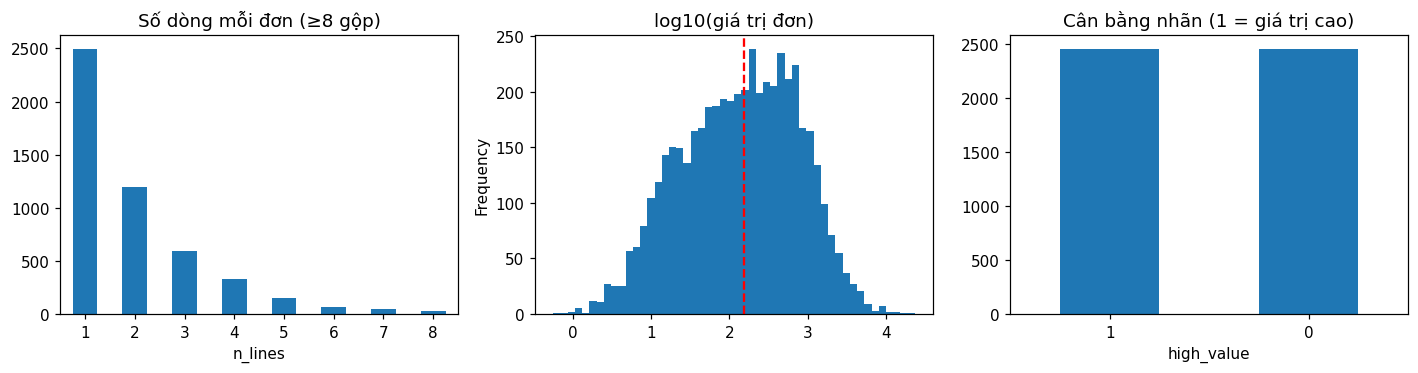

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
orders['n_lines'].clip(upper=8).value_counts().sort_index().plot(kind='bar', ax=ax[0], title='Số dòng mỗi đơn (≥8 gộp)', rot=0)
np.log10(orders['order_sales']).plot(kind='hist', bins=50, ax=ax[1], title='log10(giá trị đơn)')
ax[1].axvline(np.log10(trung_vi), color='red', ls='--')
orders['high_value'].value_counts().plot(kind='bar', ax=ax[2], title='Cân bằng nhãn (1 = giá trị cao)', rot=0)
plt.tight_layout()

## 4. Kiểm tra cấu trúc dữ liệu

Superstore là dữ liệu mẫu (mô phỏng) của Tableau. Phần này kiểm tra dữ liệu có các quan hệ mà luật kết hợp và mô hình cần khai thác hay không.

**(a) Hành vi của một khách hàng có lặp lại giữa các năm không?** Tương quan Spearman giữa doanh số của cùng khách hàng ở các năm:

In [ ]:
ds_khach_nam = df.pivot_table(index='Customer ID', columns='nam', values='Sales', aggfunc='sum', fill_value=0)
ds_khach_nam.corr(method='spearman')

nam,2015,2016,2017,2018
nam,,,,
2015,1.000,0.051,0.034,0.023
2016,0.051,1.000,-0.061,-0.000
2017,0.034,-0.061,1.000,0.004
2018,0.023,-0.000,0.004,1.000


**(b) Khách hàng có gắn với một địa điểm không?** Số bang khác nhau mà mỗi khách đã mua:

In [ ]:
df.groupby('Customer ID')['State'].nunique().describe()

,State
count,793.000
mean,5.054
std,1.908
min,1.000
25%,4.000
50%,5.000
75%,6.000
max,11.000


**(c) Các thuộc tính phân loại có liên quan nhau không?** Ví dụ tỷ trọng Category trong từng Segment:

In [ ]:
pd.crosstab(df['Segment'], df['Category'], normalize='index')

Category,Furniture,Office Supplies,Technology
Segment,,,
Consumer,0.214,0.602,0.183
Corporate,0.213,0.604,0.184
Home Office,0.204,0.604,0.192


Đo mức liên quan bằng **Cramér's V** (0 = độc lập, 1 = phụ thuộc hoàn toàn):

In [ ]:
from scipy.stats.contingency import association

cap = [('Segment', 'Category'), ('Segment', 'Sub-Category'), ('Segment', 'Ship Mode'),
       ('Region', 'Category'), ('Region', 'Ship Mode'), ('Category', 'Ship Mode')]

ket_qua = []
for a, b in cap:
    v = association(pd.crosstab(df[a], df[b]), method='cramer')
    ket_qua.append([a, b, round(v, 3)])

pd.DataFrame(ket_qua, columns=['Cột 1', 'Cột 2', "Cramér's V"])

,Cột 1,Cột 2,Cramér's V
0,Segment,Category,0.008
1,Segment,Sub-Category,0.036
2,Segment,Ship Mode,0.036
3,Region,Category,0.015
4,Region,Ship Mode,0.027
5,Category,Ship Mode,0.014


## 5. Tiền xử lý dữ liệu

In [ ]:
truoc_xu_ly = {'Số dòng': len(df), 'Số cột': 18, 'Số ô thiếu': df.isna().sum().sum(),
               'Dòng trùng': df.drop(columns=['Row ID', 'ship_days', 'nam', 'quy']).duplicated().sum()}

In [ ]:
# 1. Bỏ dòng trùng
clean = df.drop_duplicates(subset=[c for c in df.columns if c != 'Row ID'])

# 2. Bỏ cột hằng số (Country) và cột thiếu, không dùng (Postal Code, đã có City và State); bỏ cột tạm
clean = clean.drop(columns=['Country', 'Postal Code', 'nam', 'quy'])

# 3. Đổi tên cột sang dạng chữ thường, nối bằng dấu gạch dưới (chuẩn bị cho bigquery)
clean.columns = clean.columns.str.lower().str.replace(' ', '_').str.replace('-', '_')
clean = clean.rename(columns={'row_id': 'line_id'})

# 4. Ngày về dạng YYYY-MM-DD (chuẩn bị cho bigquery)
clean['order_date'] = clean['order_date'].dt.strftime('%Y-%m-%d')
clean['ship_date'] = clean['ship_date'].dt.strftime('%Y-%m-%d')

clean.head()

,line_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,region,product_id,category,sub_category,product_name,sales,ship_days
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.960,3
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,Henderson,Kentucky,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.940,3
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,Los Angeles,California,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,4
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.577,7
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,Fort Lauderdale,Florida,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368,7


In [ ]:
sau_xu_ly = {'Số dòng': len(clean), 'Số cột': clean.shape[1], 'Số ô thiếu': clean.isna().sum().sum(),
             'Dòng trùng': clean.drop(columns='line_id').duplicated().sum()}

bang_truoc_sau = pd.DataFrame({'Trước': truoc_xu_ly, 'Sau': sau_xu_ly})
bang_truoc_sau

,Trước,Sau
Số dòng,9800,9799
Số cột,18,17
Số ô thiếu,11,0
Dòng trùng,1,0


In [ ]:
clean.to_csv('/content/drive/MyDrive/Master_UEH_MIS/semester 01/04. Khai phá dữ liệu nâng cao/Đồ án/data/superstore_clean.csv', index=False)
print('Đã lưu file sạch:', clean.shape)

Đã lưu file sạch: (9799, 17)


## 6. Xếp hạng thuộc tính (mức đơn hàng)

Các thuộc tính ứng viên cho bài toán phân lớp (không dùng Sales để tránh rò rỉ nhãn). Cách xếp hạng: tính **hệ số tương quan** giữa từng thuộc tính và nhãn đơn giá trị cao. Thuộc tính phân loại (Segment, Region, tháng…) được tách thành các cột 0/1 bằng `get_dummies`, rồi lấy tương quan lớn nhất trong các cột đó.

In [ ]:
dau_don = df.drop_duplicates('Order ID').set_index('Order ID')

ung_vien = pd.DataFrame({
    'n_lines': orders['n_lines'],
    'n_subcats': orders['n_subcats'],
    'ship_days': dau_don['ship_days'],
    'month': dau_don['Order Date'].dt.month,
    'quarter': dau_don['Order Date'].dt.quarter,
    'year': dau_don['Order Date'].dt.year,
    'day_of_week': dau_don['Order Date'].dt.dayofweek,
    'segment': dau_don['Segment'],
    'region': dau_don['Region'],
    'ship_mode': dau_don['Ship Mode'],
    'state': dau_don['State']})

co_category = pd.crosstab(df['Order ID'], df['Category']).clip(upper=1).add_prefix('has_')
ung_vien = ung_vien.join(co_category)
ung_vien.head()

,n_lines,n_subcats,ship_days,month,quarter,year,day_of_week,segment,region,ship_mode,state,has_Furniture,has_Office Supplies,has_Technology
Order ID,,,,,,,,,,,,,,
CA-2015-100006,1,1,6,9,3,2015,0,Consumer,East,Standard Class,New York,0,0,1
CA-2015-100090,2,2,4,7,3,2015,2,Corporate,West,Standard Class,California,1,1,0
CA-2015-100293,1,1,4,3,1,2015,5,Home Office,South,Standard Class,Florida,0,1,0
CA-2015-100328,1,1,6,1,1,2015,2,Consumer,East,Standard Class,New York,0,1,0
CA-2015-100363,2,2,7,4,2,2015,2,Corporate,West,Standard Class,Arizona,0,1,0


In [ ]:
cot_phan_loai = ['month', 'quarter', 'year', 'day_of_week', 'segment', 'region', 'ship_mode', 'state']
ung_vien_01 = pd.get_dummies(ung_vien, columns=cot_phan_loai, dtype=int)

# Tương quan (trị tuyệt đối) của từng cột với nhãn
tuong_quan = ung_vien_01.corrwith(orders['high_value']).abs()

# Gom về thuộc tính gốc: lấy giá trị lớn nhất trong các cột 0/1 của thuộc tính đó
xep_hang = {}
for c in ung_vien.columns:
    cac_cot = [k for k in tuong_quan.index if k == c or k.startswith(c + '_')]
    xep_hang[c] = tuong_quan[cac_cot].max()

xep_hang = pd.Series(xep_hang, name='tuong_quan').sort_values(ascending=False).to_frame()
xep_hang['ket_luan'] = np.where(xep_hang['tuong_quan'] >= 0.1, 'giữ', 'loại')
xep_hang

,tuong_quan,ket_luan
n_subcats,0.440,giữ
n_lines,0.430,giữ
has_Furniture,0.362,giữ
has_Technology,0.341,giữ
has_Office Supplies,0.114,giữ
state,0.048,loại
region,0.026,loại
ship_mode,0.025,loại
month,0.021,loại
segment,0.017,loại


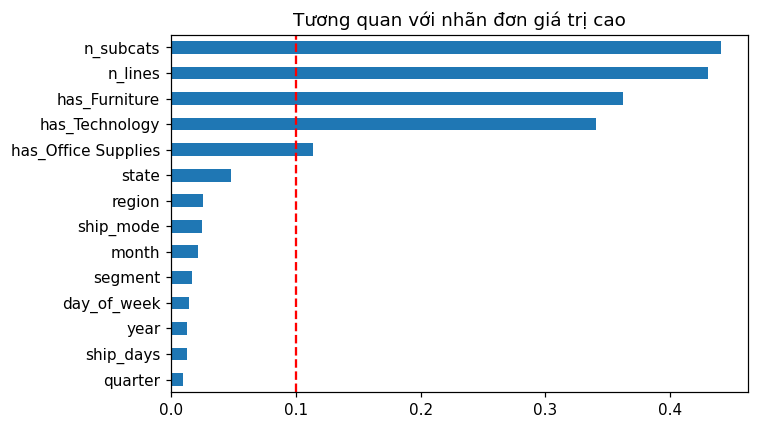

In [ ]:
xep_hang['tuong_quan'].sort_values().plot(kind='barh', figsize=(7, 4), title='Tương quan với nhãn đơn giá trị cao')
plt.axvline(0.1, color='red', ls='--')
plt.tight_layout()

In [ ]:
# n_lines và n_subcats gần như trùng nhau → chỉ giữ một
print('Tương quan n_lines và n_subcats:', round(ung_vien['n_lines'].corr(ung_vien['n_subcats']), 3))

thuoc_tinh_giu = ['n_subcats', 'has_Furniture', 'has_Technology', 'has_Office Supplies']
thuoc_tinh_giu

Tương quan n_lines và n_subcats: 0.952


['n_subcats', 'has_Furniture', 'has_Technology', 'has_Office Supplies']